# Predicting Residential Property Prices in Riyadh

**Goal:** predict the **price per m²** of a residential property in Riyadh from simple information about the deal: its **area**, **district**, and **date**.

**Data:** real sale deals published by the Saudi **Ministry of Justice** (2023 - 2025). The data was cleaned in my first project ([Saudi Real Estate Market Analysis](https://github.com/abdullrahman-ahmed/saudi-real-estate-analysis)).

**Steps**
1. Load the data and keep the deals we want to study
2. Remove extreme values
3. Explore the data
4. Prepare the features
5. Train and compare 3 models
6. Check which features matter most
7. Use the model on a new example

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

plt.rcParams["figure.figsize"] = (9, 4)

## 1. Load the data
The file contains all sale deals in **Riyadh city**. I keep only:
- **Residential** deals (commercial and agricultural land have very different prices)
- deals with **one property** (a deal with several properties has one total price, so we cannot know the price of each property)

In [2]:
df = pd.read_csv("data/riyadh_deals.csv", parse_dates=["Date"])
print("All Riyadh deals:", len(df))

df = df[(df["PropertyType"] == "Residential") & (df["Properties"] == 1)].copy()
print("Residential, single-property deals:", len(df))
df.head()

All Riyadh deals: 149896
Residential, single-property deals: 133910


,DealID,District,Date,PropertyType,Properties,Price,Area,PricePerSqm
0,18920438,المصفاة,2023-01-01,Residential,1,3235000.0,5000.00,647.00
1,18917866,المصيف,2023-01-01,Residential,1,3600000.0,900.00,4000.00
2,18923031,المعذر,2023-01-01,Residential,1,850000.0,150.00,5666.67
3,18922428,المعذر,2023-01-01,Residential,1,1900000.0,150.00,12666.67
4,18918567,المعيزلية,2023-01-01,Residential,1,1739550.0,876.65,1984.32


## 2. Remove extreme values
Some deals have very unusual prices (for example a transfer between family members for a symbolic price).
I remove the lowest 1% and the highest 1% of price per m² so they do not confuse the model.

In [3]:
low, high = df["PricePerSqm"].quantile([0.01, 0.99])
print(f"Keeping deals between {low:,.0f} and {high:,.0f} SAR per m2")

df = df[df["PricePerSqm"].between(low, high)]
print("Deals after removing extremes:", len(df))
df["PricePerSqm"].describe().round(0)

Keeping deals between 320 and 13,342 SAR per m2
Deals after removing extremes: 131241


count    131241.0
mean       2853.0
std        2516.0
min         320.0
25%        1111.0
50%        1850.0
75%        3800.0
max       13342.0
Name: PricePerSqm, dtype: float64

## 3. Explore the data
**Distribution of price per m².** Most deals are between 1,000 and 4,000 SAR/m². The mean is higher than the median because a few expensive deals pull it up, so I use the **median** when I compare groups.

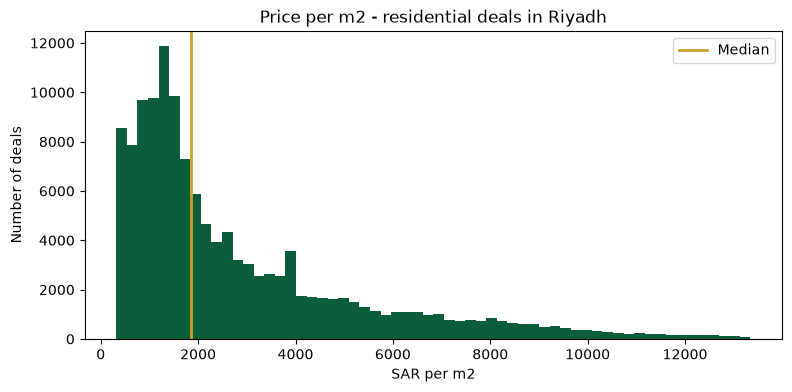

In [4]:
plt.hist(df["PricePerSqm"], bins=60, color="#0B5D3B")
plt.axvline(df["PricePerSqm"].median(), color="#C9A227", linewidth=2, label="Median")
plt.title("Price per m2 - residential deals in Riyadh")
plt.xlabel("SAR per m2")
plt.ylabel("Number of deals")
plt.legend()
plt.savefig("figures/price_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

**Median price per m² by year**

In [5]:
df["Year"] = df["Date"].dt.year
df.groupby("Year")["PricePerSqm"].agg(["count", "median"]).round(0)

,count,median
Year,,
2023,40734,1538.0
2024,65763,1840.0
2025,24744,2350.0


**The district matters a lot.** Here are the 10 most expensive districts (with at least 300 deals):

In [6]:
district_stats = df.groupby("District")["PricePerSqm"].agg(deals="count", median_price="median")
district_stats[district_stats["deals"] >= 300].sort_values("median_price", ascending=False).head(10).round(0)

,deals,median_price
District,,
النخيل,385,8912.0
حطين,1000,8684.0
الملقا,1946,8274.0
الصحافة,353,8111.0
العقيق,344,7840.0
الندى,419,7712.0
السليمانية,478,7334.0
العارض,929,6895.0
الياسمين,1459,6831.0


**Size also matters.** Small properties (under 200 m²) have a much higher price per m². They are most likely **apartments**, while large properties are mostly **land**, which is cheaper per m².

In [7]:
size_groups = pd.cut(df["Area"], bins=[0, 200, 400, 600, 1000, 5000, 1e9],
                     labels=["< 200", "200-400", "400-600", "600-1,000", "1,000-5,000", "5,000+"])
df.groupby(size_groups, observed=True)["PricePerSqm"].agg(["count", "median"]).round(0)

,count,median
Area,,
< 200,26785,5267.0
200-400,58859,1650.0
400-600,22747,1560.0
"600-1,000",18422,1282.0
"1,000-5,000",4084,1400.0
"5,000+",344,1115.0


## 4. Prepare the features
The model needs numbers, so:
- **Area**, **Year** and **Quarter** are already numbers.
- **District** is text. Riyadh has 200+ districts, so I keep districts with at least 100 deals and put the rest in a group called *Other*.
  Then I use **one-hot encoding**: each district becomes a column with 1 if the deal is in that district and 0 if not.

In [8]:
df["Quarter"] = df["Date"].dt.quarter

district_counts = df["District"].value_counts()
big_districts = district_counts[district_counts >= 100].index
df["DistrictGroup"] = df["District"].where(df["District"].isin(big_districts), "Other")
print("Districts used:", df["DistrictGroup"].nunique())

X = pd.get_dummies(df[["Area", "Year", "Quarter", "DistrictGroup"]], columns=["DistrictGroup"], dtype=int)
y = df["PricePerSqm"]
print("Model input shape:", X.shape)

Districts used: 131
Model input shape: (131241, 134)


## 5. Train and compare models
I split the data: **80% to train** the model and **20% to test** it on deals it has never seen.

I compare 3 models:
1. **Baseline**: always predict the average price (any real model must beat this)
2. **Linear Regression**: a simple model that draws a straight-line relationship
3. **Random Forest**: many decision trees that vote together. It can learn more complex patterns.

How I measure them:
- **MAE (Mean Absolute Error)**: on average, how many SAR/m² the prediction is wrong by. *Lower is better.*
- **R²**: how much of the price differences the model explains (0 = nothing, 1 = everything). *Higher is better.*

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training deals:", len(X_train), "| Test deals:", len(X_test))

results = []

# 1. Baseline
baseline_pred = np.full(len(y_test), y_train.mean())
results.append(["Baseline (average)", mean_absolute_error(y_test, baseline_pred), r2_score(y_test, baseline_pred)])

# 2. Linear Regression
linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)
results.append(["Linear Regression", mean_absolute_error(y_test, linear_pred), r2_score(y_test, linear_pred)])

# 3. Random Forest
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)
results.append(["Random Forest", mean_absolute_error(y_test, forest_pred), r2_score(y_test, forest_pred)])

results = pd.DataFrame(results, columns=["Model", "MAE (SAR/m2)", "R2"])
results.round({"MAE (SAR/m2)": 0, "R2": 2})

Training deals: 104992 | Test deals: 26249


,Model,MAE (SAR/m2),R2
0,Baseline (average),1926.0,-0.00
1,Linear Regression,848.0,0.72
2,Random Forest,618.0,0.80


**Random Forest is the best model.** Its predictions are much closer to the real prices than the baseline. The chart compares predicted and actual prices on the test deals: the closer the points are to the line, the better.

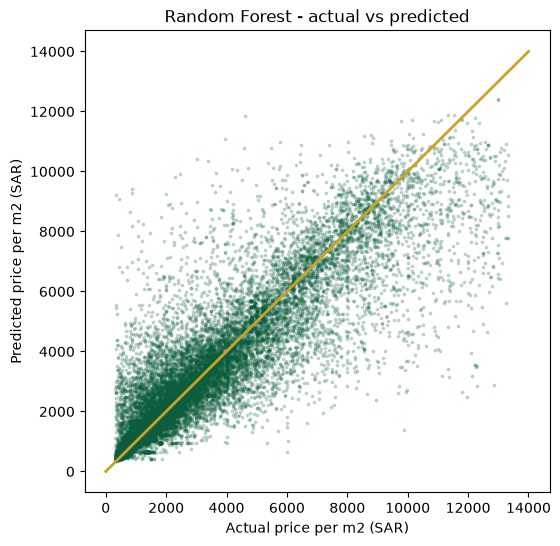

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, forest_pred, s=3, alpha=0.2, color="#0B5D3B")
plt.plot([0, 14000], [0, 14000], color="#C9A227", linewidth=2)
plt.xlabel("Actual price per m2 (SAR)")
plt.ylabel("Predicted price per m2 (SAR)")
plt.title("Random Forest - actual vs predicted")
plt.savefig("figures/actual_vs_predicted.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. What affects the price the most?
Random Forest tells us how much each feature helped. I add up all the district columns into one feature called **District**.

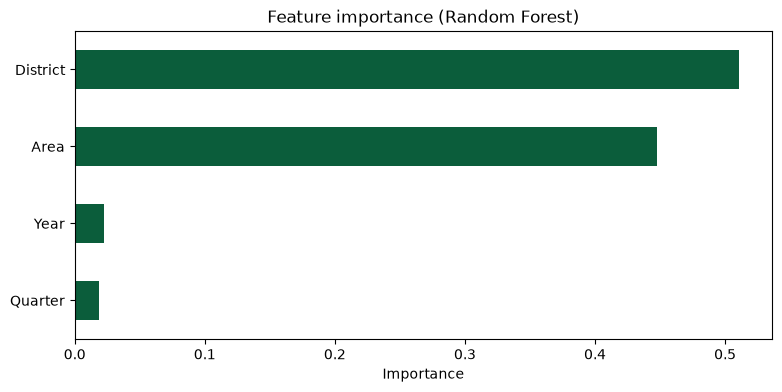

Importance in %:
District    51.1
Area        44.8
Year         2.3
Quarter      1.9


In [11]:
importance = pd.Series(forest.feature_importances_, index=X.columns)
grouped = {
    "District": importance[importance.index.str.startswith("DistrictGroup_")].sum(),
    "Area": importance["Area"],
    "Year": importance["Year"],
    "Quarter": importance["Quarter"],
}
grouped = pd.Series(grouped).sort_values()

grouped.plot(kind="barh", color="#0B5D3B")
plt.title("Feature importance (Random Forest)")
plt.xlabel("Importance")
plt.savefig("figures/feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()
print("Importance in %:")
print((grouped * 100).round(1).sort_values(ascending=False).to_string())

## 7. Try the model on a new example

In [12]:
def predict_price(area, district, year=2025, quarter=4):
    example = pd.DataFrame(0, index=[0], columns=X.columns)
    example["Area"], example["Year"], example["Quarter"] = area, year, quarter
    column = "DistrictGroup_" + (district if district in big_districts else "Other")
    example[column] = 1
    price_per_m2 = forest.predict(example)[0]
    print(f"{area} m2 in {district} ({year} Q{quarter}): {price_per_m2:,.0f} SAR/m2  ->  total about {price_per_m2 * area:,.0f} SAR")

# Same size, different districts: Al Malqa (north Riyadh) vs Al Naseem (east Riyadh)
predict_price(400, "الملقا")
predict_price(400, "النظيم")

400 m2 in الملقا (2025 Q4): 9,030 SAR/m2  ->  total about 3,611,903 SAR
400 m2 in النظيم (2025 Q4): 1,175 SAR/m2  ->  total about 469,908 SAR


## Conclusion
- The **Random Forest** model predicts the price per m² with an average error of about **600 SAR/m²** and explains about **80%** of the price differences. That is about **3 times better** than always guessing the average.
- **The district is the most important factor** (about 51%). Northern districts such as Al Malqa, Hittin and Al Nakheel are the most expensive.
- **Area is the second factor** (about 45%). Small properties have a much higher price per m² because they are mostly apartments.
- The median price per m² went up from about **1,540 SAR in 2023 to 2,350 SAR in 2025** (+53%).

**Limitations (what could make it better)**
- The data does not include the property's type (land, villa, apartment), age or street width. These would improve the model.
- Districts with few deals are grouped together as *Other*, so predictions there are less accurate.